## GenAI Fundamentals with Python

In [1]:
# Imagine Walmart wants to build a simple AI-powered assistant that can help customers and store associates with everyday store operations.

# For example, customers might ask:
# - "My grocery order is ready. Where should I collect it?"
# - "What should I do if my pickup check-in fails?"
# - "What happens if I receive a damaged product?"
# - "How can I check whether an item is available in the store?"

# Instead of manually writing every response, Walmart wants to explore how Generative AI and Python can automate these interactions while keeping responses accurate, reliable, and relevant.

# However, simply connecting Python to an AI model is not enough. We also need to understand how to control the AI's behavior, represent store information numerically, and handle situations when the AI service fails.

# The objective of this notebook is to learn these fundamentals through a fictional Walmart pickup scenario.

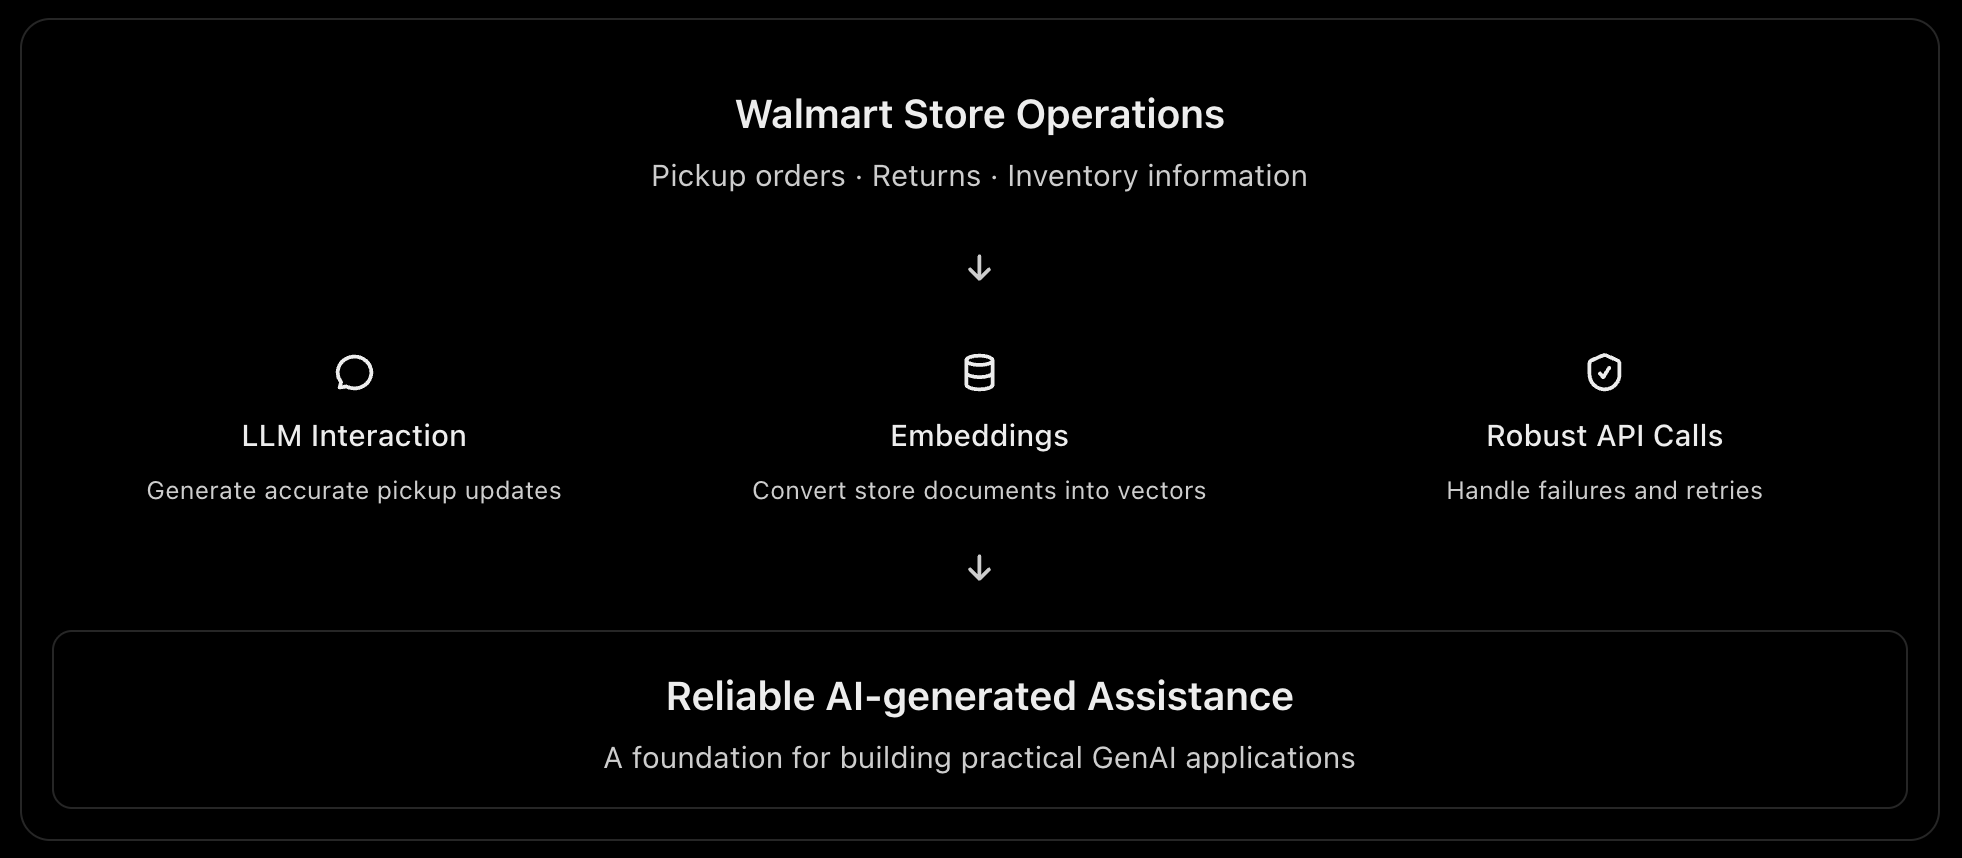

In [2]:
# Topic 1: LLM Interaction Basics

# The notebook teaches us how to send system instructions, user questions, and dynamic context to the AI model.
# It also explains how settings such as temperature, top-p, and maximum output tokens influence the generated response.

# What we learn: How Python communicates with an LLM and how to control the generated output.

In [3]:
# Topic 2: Embeddings in Practice

# How can we represent these documents in a form that an AI-powered search system could use?
# We use the OpenAI embedding model text-embedding-3-small to convert these documents into numerical vectors.

# "Customer should check in using the Walmart app"
# [0.012, -0.045, 0.087, ...]

# What we learn: How embeddings convert text into numerical vectors and prepare documents for future semantic search applications.

In [4]:
# Topic 3: Robust GenAI Calls

# What we learn: How to build more reliable AI interactions using exception handling, retries, logging, and fallback messages.

In [5]:
# LLM Interaction Basics

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(dotenv_path=".env")

client = OpenAI(timeout=20.0, max_retries=0)

TEXT_MODEL = "gpt-4.1-mini"

# Put the three prompt inputs and the sampling settings behind one function.
def ask_model(system, question, context="", *, temperature=0.2,
              top_p=1.0, max_output_tokens=160):
    # Keep the changing facts separate from the learner's question.
    user_text = f"Task: {question}\n\nReference context:\n{context}"

    # Send the role messages and generation settings to OpenAI.
    return client.responses.create(
        model=TEXT_MODEL,
        input=[
            {"role": "system", "content": system},
            {"role": "user", "content": user_text},
        ],
        temperature=temperature,
        top_p=top_p,
        max_output_tokens=max_output_tokens,
        store=False,
    )

# Define the writing rules, the request, and the mock pickup facts.
pickup_system = "Write brief, friendly updates using only the supplied facts."
pickup_question = "Write a two-sentence Walmart pickup update."
pickup_context = "Training order WMT-104 is ready. Use pickup bay 3."

# Generate the draft and inspect its status and text.
first_reply = ask_model(pickup_system, pickup_question, pickup_context)
print("Status:", first_reply.status)
print(first_reply.output_text)

Status: completed
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay 3 when you arrive.


In [ ]:
# The grass is ________
# top_p=0.1 i.e. top 10% of 30

# green
# greener
# wet
# dry
# tall
# wavy
# .
# .
# .
# .
# 30 words it can predict

### Change the facts and try the output settings

Change the pickup bay while keeping the default settings in the wrapper. Then try a small output cap. Compare the status and text. To explore top-p separately, rerun the first call with `temperature=1.0, top_p=0.8` and compare it with `temperature=1.0, top_p=1.0`.

In [7]:
# Update the order facts and leave the wrapper's generation settings alone.
changed_context = "Training order WMT-104 is ready. Use pickup bay 5."
changed_reply = ask_model(pickup_system, pickup_question, changed_context)

# Request the same draft with a much smaller output budget.
short_reply = ask_model(
    pickup_system, pickup_question, changed_context, max_output_tokens=16,
)

# Compare each response's completion status and available text.
for label, reply in [("Bay update", changed_reply), ("Small output cap", short_reply)]:
    print(label, "| status:", reply.status)
    print(reply.output_text)

Bay update | status: completed
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay 5 when you arrive.
Small output cap | status: incomplete
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay


**Takeaway** · The revised facts should lead to bay 5. If the capped reply has status `incomplete`, it may contain only part of the draft. Sampling changes can be subtle in a short, fact-based reply.

In [10]:
import openai

# Print openai version
print(openai.__version__)

import os
openai.api_key = os.getenv("OPENAI_API_KEY")

2.37.0


In [21]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4.1-mini", # https://platform.openai.com/docs/pricing
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Write a poem on my dog named Tuffy!"}],
                  temperature=0.2, # 0-2, 0 - more deterministic, 2 - more creative
                  max_tokens=256,
                  top_p=0.6
                  )
# https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create

# print(completion)
print(completion.choices[0].message.content)

Tuffy, my friend with fur so bright,  
A loyal heart, a joyful light.  
With wagging tail and playful cheer,  
You bring me comfort, always near.  

Through sunny days and stormy weather,  
We face the world, just us together.  
Your gentle eyes, your loving way,  
Make every moment a brighter day.  

Tuffy, my dog, so brave and true,  
Life’s better always spent with you.  
In every bark and every cuddle,  
You turn my days from gray to subtle.  

Forever friend, my furry guide,  
With you, my heart is open wide.  
Tuffy, my dog, my joy, my pride,  
Together always, side by side.


In [ ]:
# Embeddings in Practice

